# ThermoGuard Motor — Train the Model
The notebook downloads measured motor data, trains a neural network and saves `thermoguard_model.pt`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

INPUTS = ['i_d', 'i_q', 'u_d', 'u_q', 'motor_speed', 'coolant', 'ambient']
TARGETS = ['pm', 'stator_winding', 'stator_tooth', 'stator_yoke']
NAMES = ['Rotor magnet', 'Stator winding', 'Stator tooth', 'Stator yoke']
DT = 2.0
MODEL_PATH = Path('thermoguard_model.pt')
torch.set_num_threads(2)

pd.options.display.float_format = "{:.2f}".format


## 1. Fetch the dataset
[Electric Motor Temperature](https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature), Kirchgassner, Wallscheid and Bocker, Paderborn University. [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Version 3; sampled every 0.5 seconds.

In [2]:
import urllib.request
import zipfile
import hashlib

csv_path = Path('measures_v2.csv')
if not csv_path.exists():
    url = ('https://www.kaggle.com/api/v1/datasets/download/'
           'wkirgsn/electric-motor-temperature?datasetVersionNumber=3')
    print('Downloading measured motor data...')
    urllib.request.urlretrieve(url, 'motor_data.zip')
    with zipfile.ZipFile('motor_data.zip') as archive:
        with archive.open('measures_v2.csv') as source, csv_path.open('wb') as target:
            import shutil
            shutil.copyfileobj(source, target)

checksum = hashlib.sha256(csv_path.read_bytes()).hexdigest()
assert checksum == '78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad'
data = pd.read_csv(csv_path, dtype='float32')
assert np.isfinite(data[INPUTS + TARGETS].to_numpy()).all()
print(f'{len(data):,} measured rows | {data.profile_id.nunique()} drives')
print('INPUTS — currents (A), voltages (V), speed (rpm), temperatures (C)')
display(data[INPUTS].head().round(2))
print('CORRESPONDING MEASURED OUTPUTS — temperatures (C)')
display(data[TARGETS].head().round(2))


1,330,816 measured rows | 69 drives
INPUTS — currents (A), voltages (V), speed (rpm), temperatures (C)


,i_d,i_q,u_d,u_q,motor_speed,coolant,ambient
0,0.00,0.00,-0.35,-0.45,0.00,18.81,19.85
1,0.00,-0.00,-0.31,-0.33,0.00,18.82,19.85
2,0.00,0.00,-0.37,-0.44,0.00,18.83,19.85
3,0.00,0.00,-0.32,-0.33,0.01,18.84,19.85
4,-0.06,0.04,-0.33,-0.47,0.00,18.86,19.85


CORRESPONDING MEASURED OUTPUTS — temperatures (C)


,pm,stator_winding,stator_tooth,stator_yoke
0,24.55,19.09,18.29,18.32
1,24.54,19.09,18.29,18.31
2,24.54,19.09,18.29,18.33
3,24.55,19.08,18.29,18.33
4,24.57,19.08,18.29,18.33


## 2. Split complete drives
Use 48 drives for training, seven for validation and 14 for testing. Each drive stays in one group. Retain every fourth row for a two-second sample interval.

In [3]:
# Retain one row every 2 seconds, separately inside each drive.
profiles = {int(pid): (g[INPUTS].to_numpy()[::4].copy(),
                       g[TARGETS].to_numpy()[::4].copy())
            for pid, g in data.groupby('profile_id', sort=True)}
ids = np.random.default_rng(42).permutation(sorted(profiles)).tolist()
split = {'train': ids[:48], 'validation': ids[48:55], 'test': ids[55:]}
training_inputs = np.concatenate([profiles[p][0] for p in split['train']])
fallback = np.median(training_inputs, axis=0)
print('Drive split:', {name: len(group) for name, group in split.items()})


Drive split: {'train': 48, 'validation': 7, 'test': 14}


## 3. Prepare the inputs
Seven measurements become 49 features: current readings, recent history, sensor availability and elapsed time. Measured target temperatures never enter these features.

In [4]:
def make_features(readings, fallback):
    """Use only current/past inputs; never use measured target temperatures."""
    x = np.array(readings, dtype=np.float32, copy=True)
    if x.ndim != 2 or x.shape[1] != 7 or len(x) == 0:
        raise ValueError('Expected at least one row of seven operating measurements.')
    if not np.isfinite(x[:, 6]).all():
        raise ValueError('Ambient temperature must remain available.')
    available = np.isfinite(x).astype(np.float32)
    ages = np.zeros_like(x)
    # Missing input: hold the last reading for 20 s, then use a training median.
    for channel in range(7):
        last, age = float(fallback[channel]), 0.0
        for row in range(len(x)):
            if available[row, channel]:
                last, age = float(x[row, channel]), 0.0
            else:
                age += DT
                x[row, channel] = last if age <= 20 else fallback[channel]
            ages[row, channel] = min(age, 900) / 900
    current_squared = x[:, 0] ** 2 + x[:, 1] ** 2
    power_proxy = np.abs(x[:, 0] * x[:, 2] + x[:, 1] * x[:, 3])
    base = np.column_stack([x, current_squared, np.abs(x[:, 4]), power_proxy])
    clues = [base]
    # Heat builds and cools gradually: remember four different lengths of history.
    for seconds in [10, 60, 300, 900]:
        history = pd.DataFrame(base[:, [0, 1, 4, 5, 7, 9]]).ewm(
            alpha=1 - np.exp(-DT / seconds), adjust=False).mean()
        clues.append(history.to_numpy(dtype=np.float32))
    elapsed = np.minimum(np.arange(len(x)) * DT, 3600)[:, None] / 3600
    return np.column_stack(clues + [available, ages, elapsed]).astype(np.float32)

def coolant_dropout(readings, duration=120):
    """Remove only a copy of the coolant input, 45% into a drive."""
    damaged = readings.copy()
    start = int(len(damaged) * 0.45)
    end = min(len(damaged), start + int(duration / DT))
    damaged[start:end, 5] = np.nan
    return damaged, start, end


In [5]:
def prepare_examples(ids):
    features, answers = [], []
    for pid in ids:
        readings, temperatures = profiles[pid]
        # Learn with healthy inputs and a missing coolant input.
        for variant in [readings, coolant_dropout(readings)[0]]:
            clues = make_features(variant, fallback)
            rows = np.linspace(0, len(readings) - 1, min(1200, len(readings))).astype(int)
            features.append(clues[rows])
            answers.append((temperatures[rows] - readings[rows, 6, None]) / 50)
    return np.concatenate(features), np.concatenate(answers)

x, y = prepare_examples(split['train'])
vx, vy = prepare_examples(split['validation'])
mean, scale = x.mean(0), x.std(0)
constant = scale < 1e-5
scale[constant] = 1
x = torch.tensor((x - mean) / scale, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)
vx = torch.tensor((vx - mean) / scale, dtype=torch.float32)
vy = torch.tensor(vy, dtype=torch.float32)
print('Training input shape:', tuple(x.shape))
print('Training output shape:', tuple(y.shape))


Training input shape: (113354, 49)
Training output shape: (113354, 4)


## 4. Build the neural network
**49 inputs → 96 units → 64 units → 4 outputs.** Outputs are temperature rises above ambient, divided by 50 during training.

In [6]:
class MotorNet(nn.Module):
    """49 clues, two hidden layers, and four temperature-rise answers."""
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(49, 96), nn.ReLU(),
                                    nn.Linear(96, 64), nn.ReLU(), nn.Linear(64, 4))

    def forward(self, x):
        return self.layers(x)

torch.manual_seed(11)
net = MotorNet()
with torch.no_grad():
    net.layers[0].weight[:, constant] = 0
print(net)
print('Trainable parameters:', sum(p.numel() for p in net.parameters()))


MotorNet(
  (layers): Sequential(
    (0): Linear(in_features=49, out_features=96, bias=True)
    (1): ReLU()
    (2): Linear(in_features=96, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)
Trainable parameters: 11268


## 5. Train
AdamW updates the weights to reduce squared error. Keep the best validation result and stop after ten epochs without enough improvement.

Epoch  1: validation MAE = 3.359 C
Epoch  6: validation MAE = 1.735 C
Epoch 11: validation MAE = 1.520 C
Epoch 16: validation MAE = 1.456 C
Epoch 21: validation MAE = 1.430 C
Epoch 25: validation MAE = 1.433 C
Training complete. Best validation MAE: 1.407 C


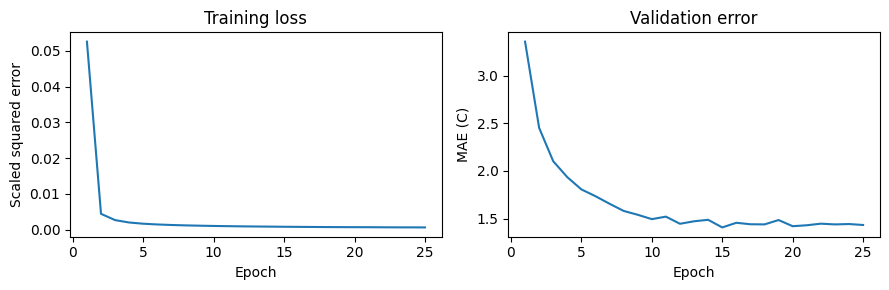

In [7]:
optimizer = torch.optim.AdamW(net.parameters(), lr=0.0015, weight_decay=0.0001)
rng = np.random.default_rng(11)
best_error, stale, best_weights = float('inf'), 0, None
history = []

for epoch in range(65):
    net.train()
    total_loss = 0.0
    order = rng.permutation(len(x))
    for start in range(0, len(x), 1024):
        rows = order[start:start + 1024]
        loss = ((net(x[rows]) - y[rows]) ** 2).mean()
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 5)
        optimizer.step()
        total_loss += loss.item() * len(rows)
    net.eval()
    with torch.no_grad():
        validation_error = (net(vx) - vy).abs().mean().item() * 50
    history.append([epoch + 1, total_loss / len(x), validation_error])
    if validation_error < best_error - 0.003:
        best_error, stale = validation_error, 0
        best_weights = {k: v.detach().clone() for k, v in net.state_dict().items()}
    else:
        stale += 1
    if epoch % 5 == 0 or stale >= 10:
        print(f'Epoch {epoch + 1:2}: validation MAE = {validation_error:.3f} C')
    if stale >= 10:
        break

assert best_weights is not None
net.load_state_dict(best_weights)
net.eval()
print(f'Training complete. Best validation MAE: {best_error:.3f} C')
learning = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(learning[:, 0], learning[:, 1])
axes[0].set(xlabel='Epoch', ylabel='Scaled squared error', title='Training loss')
axes[1].plot(learning[:, 0], learning[:, 2])
axes[1].set(xlabel='Epoch', ylabel='MAE (C)', title='Validation error')
plt.tight_layout()
plt.show()


## 6. Test on unseen drives
MAE is the average absolute temperature error. Each test drive has equal weight. Initial internal temperature is unknown, so errors can be larger at the start of a drive.

,Component,Test MAE (C)
0,Rotor magnet,3.987
1,Stator winding,1.829
2,Stator tooth,1.610
3,Stator yoke,1.155


Mean across 14 test drives and four components: 2.145 C
Example inputs from test drive 21:


,i_d,i_q,u_d,u_q,motor_speed,coolant,ambient
0,-189.00,83.55,-122.16,44.25,4499.75,18.72,19.47
1,-191.37,82.93,-127.92,27.89,4499.96,18.70,21.86
2,-83.55,1.06,-5.33,131.39,4499.95,19.27,21.95
3,-84.64,1.05,-5.20,131.33,4499.96,18.62,22.38
4,-84.71,1.05,-5.19,131.36,4499.96,19.47,22.29


Measured and predicted outputs for those same rows:


,Rotor magnet measured,Rotor magnet predicted,Stator winding measured,Stator winding predicted,Stator tooth measured,Stator tooth predicted,Stator yoke measured,Stator yoke predicted
0,20.86,92.43,19.78,98.06,18.82,74.05,18.74,50.64
1082,87.16,93.78,104.79,106.36,78.97,80.07,54.12,54.79
2165,53.07,54.13,44.83,43.63,39.45,40.97,32.45,32.31
3247,46.32,47.50,42.91,45.00,38.64,40.37,31.31,32.17
4330,45.38,47.22,42.79,45.15,38.47,40.58,31.32,32.55


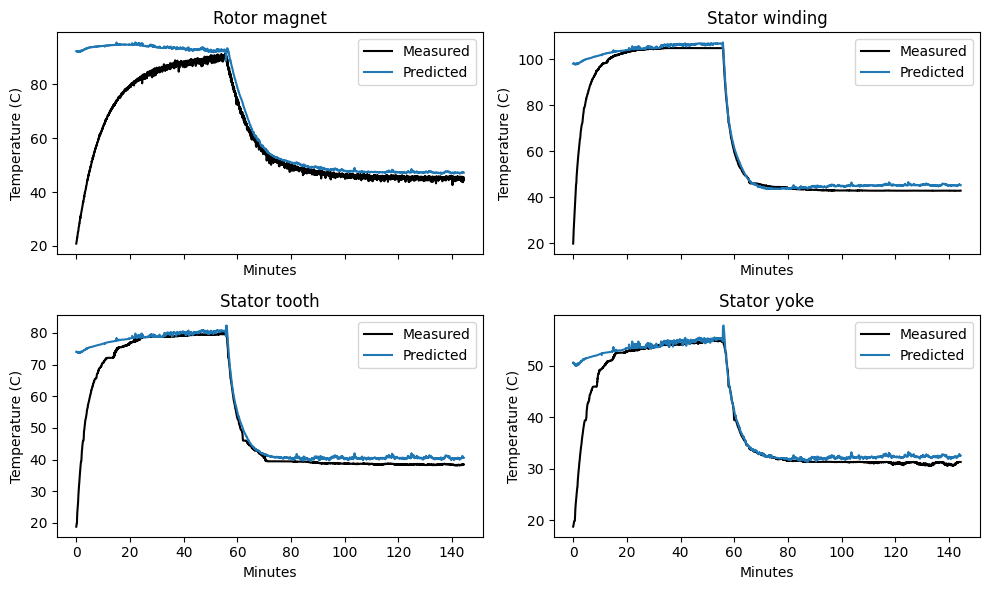

In [9]:
def estimate(readings):
    clues = make_features(readings, fallback)
    scaled = (clues - mean) / scale
    with torch.no_grad():
        rise = net(torch.tensor(scaled, dtype=torch.float32)).numpy()
    return readings[:, 6, None] + 50 * rise

errors = []
for pid in split['test']:
    readings, measured = profiles[pid]
    errors.append(np.abs(estimate(readings) - measured).mean(axis=0))
mae = np.mean(errors, axis=0)
display(pd.DataFrame({'Component': NAMES, 'Test MAE (C)': [f'{value:.3f}' for value in mae]}))
print(f'Mean across 14 test drives and four components: {mae.mean():.3f} C')

pid = split['test'][0]
readings, measured = profiles[pid]
estimated = estimate(readings)
rows = np.linspace(0, len(readings) - 1, 5).astype(int)
print(f'Example inputs from test drive {pid}:')
display(pd.DataFrame(readings[rows], columns=INPUTS).round(2))
print('Measured and predicted outputs for those same rows:')
comparison = pd.DataFrame(index=rows)
for j, name in enumerate(NAMES):
    comparison[name + ' measured'] = measured[rows, j]
    comparison[name + ' predicted'] = estimated[rows, j]
display(comparison.round(2))

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
minutes = np.arange(len(readings)) * DT / 60
for j, ax in enumerate(axes.flat):
    ax.plot(minutes, measured[:, j], color='black', label='Measured')
    ax.plot(minutes, estimated[:, j], label='Predicted')
    ax.set(title=NAMES[j], xlabel='Minutes', ylabel='Temperature (C)')
    ax.legend()
plt.tight_layout()
plt.show()


In [10]:
from sklearn.metrics import r2_score

assert DT == 2.0, f'This is not the 2 s model (DT={DT})'

# Pooled R² per component over all test-drive rows
y_true = np.concatenate([profiles[pid][1] for pid in split['test']])
y_pred = np.concatenate([estimate(profiles[pid][0]) for pid in split['test']])

r2 = r2_score(y_true, y_pred, multioutput='raw_values')
display(pd.DataFrame({
    'Component': NAMES,
    'Test R²': [f'{v:.4f}' for v in r2],
    'R² error (1 - R²)': [f'{1 - v:.4f}' for v in r2],
}))
print(f'Mean R² (2 s model): {r2.mean():.4f}')
print(f'Mean R² error (1 - R²): {1 - r2.mean():.4f}')

# Per-drive average (equal weight per drive, like your MAE)
per_drive = [r2_score(profiles[pid][1], estimate(profiles[pid][0]), multioutput='raw_values')
             for pid in split['test']]
print('Per-drive-averaged R²:', np.round(np.mean(per_drive, axis=0), 4))

,Component,Test R²,R² error (1 - R²)
0,Rotor magnet,0.9138,0.0862
1,Stator winding,0.9899,0.0101
2,Stator tooth,0.9883,0.0117
3,Stator yoke,0.9922,0.0078


Mean R² (2 s model): 0.9711
Mean R² error (1 - R²): 0.0289
Per-drive-averaged R²: [-10.4757   0.9488   0.9047   0.9043]


## 7. Save the model
Save the learned weights together with input scaling and missing-reading values. Notebook 02 loads this file.

In [11]:
checkpoint = {
    'weights': best_weights,
    'mean': mean.tolist(), 'scale': scale.tolist(), 'fallback': fallback.tolist(),
    'inputs': INPUTS, 'targets': TARGETS, 'dt': DT, 'split': split,
    'best_validation_mae_c': best_error, 'history': history,
    'slider_min': training_inputs.min(axis=0).tolist(),
    'slider_max': training_inputs.max(axis=0).tolist(),
    'slider_default': profiles[split['train'][0]][0][len(profiles[split['train'][0]][0]) // 2].tolist(),
    'version': 'thermoguard-colab-v1',
}
torch.save(checkpoint, MODEL_PATH)
assert MODEL_PATH.exists()
print(f'Model saved: {MODEL_PATH.name} ({MODEL_PATH.stat().st_size / 1024:.1f} KB)')


Model saved: thermoguard_model.pt (49.3 KB)


In [12]:
from google.colab import files
files.download(str(MODEL_PATH))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>